# 1.1 Wrangling dan EDA

## 1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa  tidak boleh sama! (akan ditentukan) 

6/9/2015-8/9/2015		

8/18/2015-9/2/2015

## 2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv! 

In [1]:
import pandas as pd
import os

In [2]:
# Lokasi file sumber
source = os.getcwd()
csv_file_path = os.path.join(source, "archive", "events.csv")

# Folder output
output_dir = os.path.join(source, "hasil_filter")
os.makedirs(output_dir, exist_ok=True)

# Batas periode training dan testing
train_start = pd.Timestamp("2015-06-09")
train_end   = pd.Timestamp("2015-08-09")

test_start  = pd.Timestamp("2015-08-18")
test_end    = pd.Timestamp("2015-09-02")

# Baca data
df = pd.read_csv(csv_file_path)

# Konversi Unix timestamp (milidetik) menjadi tanggal
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

# Filter periode training
training = df[
    (df["datetime"] >= train_start) &
    (df["datetime"] < train_end + pd.Timedelta(days=1))
].copy()

# Filter periode testing
testing = df[
    (df["datetime"] >= test_start) &
    (df["datetime"] < test_end + pd.Timedelta(days=1))
].copy()

# Simpan ke CSV
training.to_csv(
    os.path.join(output_dir, "events_training.csv"),
    index=False
)

testing.to_csv(
    os.path.join(output_dir, "events_testing.csv"),
    index=False
)

print("Filtering selesai.")
print("Jumlah data training:", len(training))
print("Jumlah data testing:", len(testing))
print("File tersimpan di:", output_dir)

Filtering selesai.
Jumlah data training: 1300229
Jumlah data testing: 288220
File tersimpan di: d:\Semester 7\GSD\UTS\hasil_filter


## 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan! 

Import data ke Neo4j -> Hitung jenis dan jumlah node -> Hasil subgraph

In [3]:
import pandas as pd

training_path = "hasil_filter/events_training.csv"

df = pd.read_csv(training_path)

print("Ukuran data:", df.shape)
print("Nama kolom:", df.columns.tolist())
display(df.head())

Ukuran data: (1300229, 6)
Nama kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'datetime']


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433827080702,225284,view,385769,NaN,2015-06-09 05:18:00.702
1,1433826000286,587247,view,422583,NaN,2015-06-09 05:00:00.286
2,1433825849786,634081,view,449489,NaN,2015-06-09 04:57:29.786
3,1433826959637,743979,view,108936,NaN,2015-06-09 05:15:59.637
4,1433826407028,959982,view,346139,NaN,2015-06-09 05:06:47.028


In [4]:
import os
from neo4j import GraphDatabase
from tqdm.auto import tqdm

In [10]:
training_path = os.path.join(
    "hasil_filter",
    "events_training.csv"
)

if not os.path.exists(training_path):
    raise FileNotFoundError(
        f"File tidak ditemukan: {training_path}"
    )

# Koneksi ke Neo4j
URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "12345678"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

driver.verify_connectivity()

# Membuat constraint agar ID node unik
def create_constraints(tx):
    tx.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)
    tx.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

# Mengimpor satu batch
def import_batch(tx, records):
    query = """
    UNWIND $records AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """
    tx.run(query, records=records)

# Impor secara bertahap
batch_size = 5000

try:
    with driver.session(database="neo4j") as session:

        session.execute_write(create_constraints)

        chunks = pd.read_csv(
            training_path,
            chunksize=batch_size
        )

        for chunk in tqdm(chunks, desc="Impor training"):

            # Mengubah NaN menjadi None agar aman dikirim ke Neo4j
            chunk = chunk.astype(object).where(
                pd.notna(chunk), None
            )

            records = chunk.to_dict(orient="records")

            session.execute_write(
                import_batch,
                records
            )

    print("Impor graf training selesai.")

finally:
    driver.close()

Impor training: 0it [00:00, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=8, column=5, offset=142>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 142, 'line': 8, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $records AS row\n\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row\n        WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {\n            timestamp: row.timestamp\n        }]->(i)\n\n       

Impor graf training selesai.


In [11]:
driver = GraphDatabase.driver(
    "bolt://localhost:7687",
    auth=("neo4j", "12345678")
)

# Cypher untuk menghitung jumlah setiap jenis node
query_nodes = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label, count(*) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_nodes)
    data_nodes = [record.data() for record in result]

df_nodes = pd.DataFrame(data_nodes)
display(df_nodes)

driver.close()

,label,jumlah
0,Visitor,679027
1,Item,169666


In [12]:
driver = GraphDatabase.driver(
    "bolt://localhost:7687",
    auth=("neo4j", "12345678")
)

query_relationships = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_relationships)
    data_relationships = [record.data() for record in result]

df_relationships = pd.DataFrame(data_relationships)
display(df_relationships)

driver.close()


,jenis_relasi,jumlah
0,VIEWED,1256684
1,ADDED_TO_CART,32809
2,BOUGHT,10736


Subgraph dibangun dari dataset `events_training.csv` yang telah difilter berdasarkan periode training. Data tersebut diimpor ke Neo4j menggunakan Python API dan Cypher untuk membentuk simpul serta hubungan antar-simpul.

Query Cypher yang digunakan untuk mengetahui komposisi simpul adalah:

```cypher
MATCH (n)
UNWIND labels(n) AS label
RETURN label, count(*) AS jumlah
ORDER BY jumlah DESC;
```

Penjelasan query:

1. `MATCH (n)` mengambil seluruh simpul pada database yang dipilih.
2. `UNWIND labels(n) AS label` mengambil label setiap simpul untuk mengidentifikasi jenisnya.
3. `RETURN label, count(*) AS jumlah` menghitung jumlah simpul berdasarkan label.
4. `ORDER BY jumlah DESC` mengurutkan hasil dari jumlah terbesar ke terkecil.

Query tersebut dijalankan melalui Neo4j Python Driver, lalu hasilnya diubah menjadi DataFrame menggunakan pandas agar lebih mudah ditampilkan dan dianalisis.

Berdasarkan struktur graf yang dibangun, simpul `Visitor` merepresentasikan pengguna (User), sedangkan simpul `Item` merepresentasikan barang yang menjadi objek interaksi. Jumlah masing-masing simpul diperoleh dari hasil query pada database Neo4j.

**Hasil komposisi simpul:**

| Jenis simpul | Jumlah |
|---|---:|
| Visitor | [679027] |
| Item | [169666] |

Graf juga memiliki hubungan interaksi, seperti `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`, yang merepresentasikan aktivitas pengguna terhadap barang.

## 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)

Membentuk matriks terlebih dahulu

In [15]:
from scipy.sparse import csr_matrix
import numpy as np

# Mengambil pasangan User-Item yang memiliki relasi
query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN DISTINCT v.visitorId AS visitor_id,
                i.itemId AS item_id
"""

user_to_idx = {}
item_to_idx = {}
rows = []
cols = []

with driver.session(database="neo4j") as session:
    result = session.run(query)

    for record in result:
        user_id = record["visitor_id"]
        item_id = record["item_id"]

        if user_id not in user_to_idx:
            user_to_idx[user_id] = len(user_to_idx)

        if item_id not in item_to_idx:
            item_to_idx[item_id] = len(item_to_idx)

        rows.append(user_to_idx[user_id])
        cols.append(item_to_idx[item_id])

# Matriks User x Item dengan nilai biner
values = np.ones(len(rows), dtype=np.uint8)

X_user = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_to_idx), len(item_to_idx)),
    dtype=np.uint8
)

# Memastikan nilai tetap biner jika ada pasangan duplikat
X_user.data[:] = 1

print("Dimensi matriks:", X_user.shape)
print("Jumlah User:", X_user.shape[0])
print("Jumlah Item:", X_user.shape[1])
print("Jumlah pasangan interaksi unik:", X_user.nnz)
print("Ukuran matriks padat:", X_user.shape[0] * X_user.shape[1])


Dimensi matriks: (679027, 169666)
Jumlah User: 679027
Jumlah Item: 169666
Jumlah pasangan interaksi unik: 1015992
Ukuran matriks padat: 115207794982


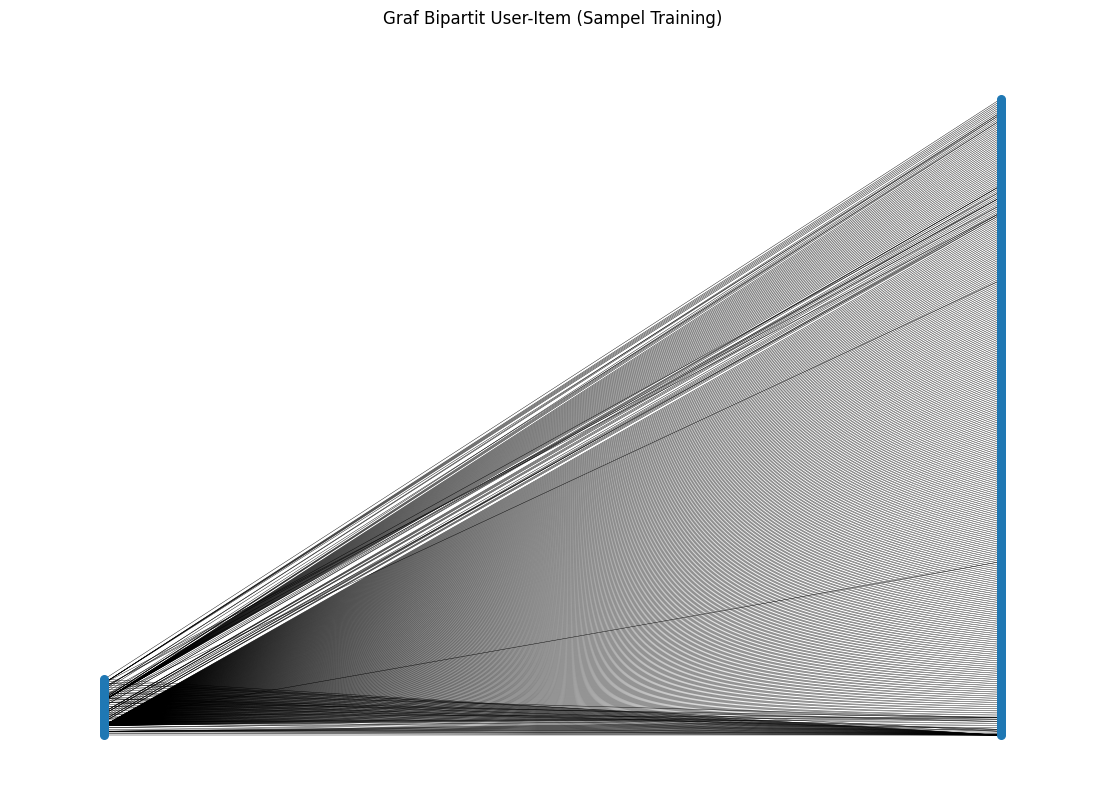

Node pada graf sampel: 361
Edge pada graf sampel: 385


In [16]:
import networkx as nx
import matplotlib.pyplot as plt

# Pilih maksimal 30 User pertama
jumlah_user_plot = min(30, len(user_to_idx))
selected_users = list(user_to_idx.keys())[:jumlah_user_plot]
selected_user_idx = {
    user_to_idx[user_id] for user_id in selected_users
}

# Bangun graf bipartit dari interaksi sampel
G_user = nx.Graph()

for user_id in selected_users:
    G_user.add_node(
        f"U:{user_id}",
        bipartite="user"
    )

for user_id in selected_users:
    u_idx = user_to_idx[user_id]

    start = X_user.indptr[u_idx]
    end = X_user.indptr[u_idx + 1]

    for item_idx in X_user.indices[start:end]:
        item_id = list(item_to_idx.keys())[item_idx]

        G_user.add_node(
            f"I:{item_id}",
            bipartite="item"
        )
        G_user.add_edge(
            f"U:{user_id}",
            f"I:{item_id}"
        )

user_nodes = [
    node for node, attr in G_user.nodes(data=True)
    if attr["bipartite"] == "user"
]
item_nodes = [
    node for node, attr in G_user.nodes(data=True)
    if attr["bipartite"] == "item"
]

pos = {}

pos.update({
    node: (0, idx)
    for idx, node in enumerate(user_nodes)
})
pos.update({
    node: (1, idx)
    for idx, node in enumerate(item_nodes)
})

plt.figure(figsize=(14, 10))
nx.draw_networkx(
    G_user,
    pos=pos,
    nodelist=user_nodes + item_nodes,
    node_size=30,
    with_labels=False,
    width=0.3
)
plt.title("Graf Bipartit User-Item (Sampel Training)")
plt.axis("off")
plt.show()

print("Node pada graf sampel:", G_user.number_of_nodes())
print("Edge pada graf sampel:", G_user.number_of_edges())

Vector Space Modelling (VSM) dilakukan dengan merepresentasikan setiap User sebagai vektor berdasarkan interaksinya terhadap Item. Matriks yang dibentuk memiliki baris berupa User unik dan kolom berupa Item unik. Nilai 1 menunjukkan adanya interaksi antara User dan Item, sedangkan nilai 0 menunjukkan tidak adanya interaksi.

Matriks VSM User memiliki shape **([679027], [169666])**. Matriks disimpan menggunakan format sparse matrix untuk menghemat memori karena sebagian besar pasangan User–Item tidak memiliki interaksi.

Visualisasi NetworkX menampilkan graf bipartit yang menghubungkan User dengan Item yang pernah diinteraksikan. Visualisasi hanya menggunakan sampel User agar struktur graf dapat diamati dengan lebih jelas, sedangkan matriks VSM dibentuk dari seluruh data interaksi training yang tersedia di database.

## 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)! 

In [17]:
# VSM Item: baris = Item, kolom = User
X_item = X_user.T.tocsr()

print("Shape VSM Item:", X_item.shape)
print("Jumlah Item:", X_item.shape[0])
print("Jumlah User:", X_item.shape[1])
print("Jumlah pasangan interaksi:", X_item.nnz)
print("Jumlah dimensi:", X_item.ndim)

Shape VSM Item: (169666, 679027)
Jumlah Item: 169666
Jumlah User: 679027
Jumlah pasangan interaksi: 1015992
Jumlah dimensi: 2


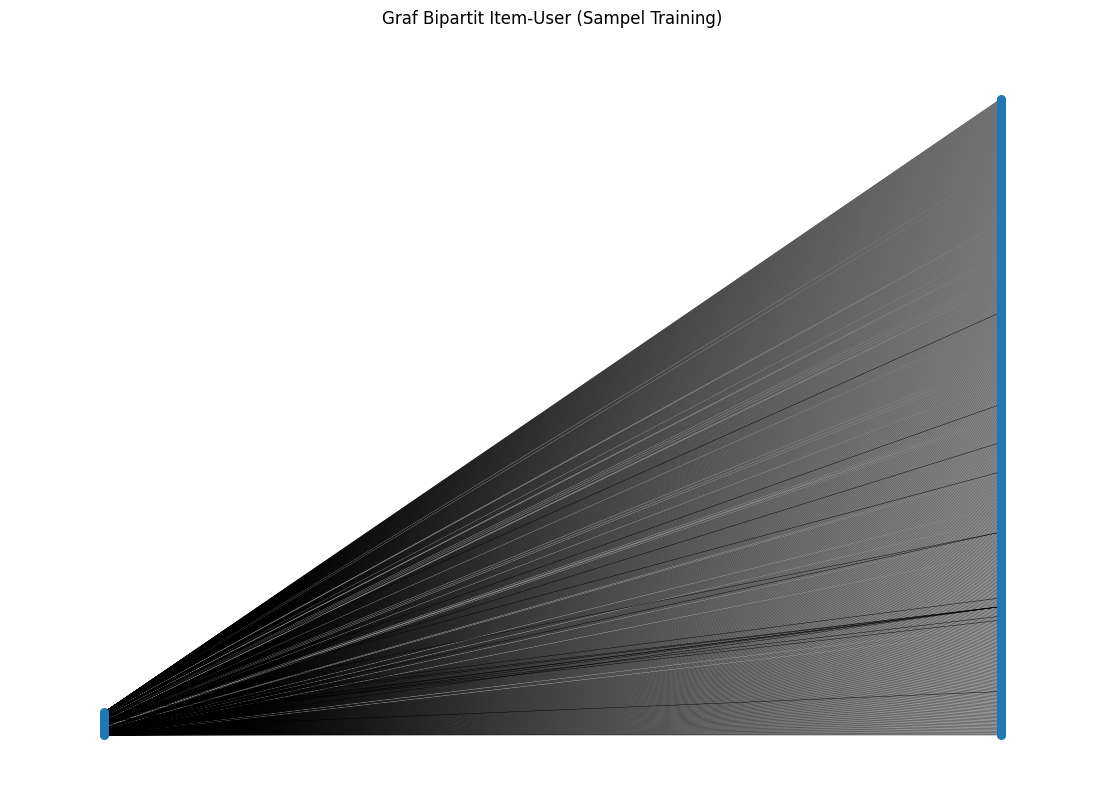

Jumlah node sampel: 833
Jumlah edge sampel: 819


In [19]:
# Membuat peta indeks kembali ke ID asli
idx_to_user = {
    idx: user_id
    for user_id, idx in user_to_idx.items()
}
idx_to_item = {
    idx: item_id
    for item_id, idx in item_to_idx.items()
}

# Ambil maksimal 30 Item pertama
jumlah_item_plot = min(30, X_item.shape[0])
selected_item_idx = list(range(jumlah_item_plot))

G_item = nx.Graph()

for item_idx in selected_item_idx:
    item_id = idx_to_item[item_idx]
    item_node = f"I:{item_id}"

    G_item.add_node(
        item_node,
        bipartite="item"
    )

    # Cari User yang memiliki interaksi dengan Item ini
    start = X_item.indptr[item_idx]
    end = X_item.indptr[item_idx + 1]

    for user_idx in X_item.indices[start:end]:
        user_id = idx_to_user[user_idx]
        user_node = f"U:{user_id}"

        G_item.add_node(
            user_node,
            bipartite="user"
        )

        G_item.add_edge(item_node, user_node)

# Pisahkan posisi Item dan User
item_nodes = [
    n for n, d in G_item.nodes(data=True)
    if d["bipartite"] == "item"
]
user_nodes = [
    n for n, d in G_item.nodes(data=True)
    if d["bipartite"] == "user"
]

pos = {}
pos.update({
    node: (0, idx)
    for idx, node in enumerate(item_nodes)
})
pos.update({
    node: (1, idx)
    for idx, node in enumerate(user_nodes)
})

plt.figure(figsize=(14, 10))
nx.draw_networkx(
    G_item,
    pos=pos,
    node_size=30,
    with_labels=False,
    width=0.3
)
plt.title("Graf Bipartit Item-User (Sampel Training)")
plt.axis("off")
plt.show()

print("Jumlah node sampel:", G_item.number_of_nodes())
print("Jumlah edge sampel:", G_item.number_of_edges())

VSM pada simpul Item dilakukan dengan merepresentasikan setiap Item sebagai vektor berdasarkan interaksinya dengan User. Matriks dibentuk dengan baris berupa Item unik dan kolom berupa User unik. Nilai 1 menunjukkan adanya interaksi antara Item dan User, sedangkan nilai 0 menunjukkan tidak adanya interaksi.

Matriks VSM Item memiliki shape **([169666], [679027])**, dengan jumlah dimensi matriks sebanyak 2. Matriks disimpan dalam format sparse matrix untuk menghemat penggunaan memori karena sebagian besar pasangan Item–User tidak memiliki interaksi.

Visualisasi menggunakan NetworkX menunjukkan graf bipartit yang menghubungkan Item dengan User yang pernah berinteraksi dengannya. Visualisasi menggunakan sampel Item agar struktur hubungan dapat diamati dengan lebih jelas, sedangkan matriks VSM dibentuk berdasarkan seluruh pasangan interaksi unik dalam data training.

Karakteristik VSM Item dapat digunakan untuk memahami pola User yang berinteraksi dengan setiap Item dan menjadi dasar untuk analisis proyeksi Item pada tahap selanjutnya.


## 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)! 

In [21]:
# Membandingkan VSM User dan VSM Item

jumlah_user = X_user.shape[0]
jumlah_item = X_user.shape[1]

print("=== VSM USER ===")
print("Shape:", X_user.shape)
print("Jumlah User:", jumlah_user)
print("Jumlah Item:", jumlah_item)
print("Jumlah interaksi:", X_user.nnz)

print("\n=== VSM ITEM ===")
print("Shape:", X_item.shape)
print("Jumlah Item:", X_item.shape[0])
print("Jumlah User:", X_item.shape[1])
print("Jumlah interaksi:", X_item.nnz)

print("\n=== PERBANDINGAN ===")
if jumlah_user > jumlah_item:
    print("Jumlah User lebih banyak daripada Item.")
elif jumlah_item > jumlah_user:
    print("Jumlah Item lebih banyak daripada User.")
else:
    print("Jumlah User dan Item sama.")

=== VSM USER ===
Shape: (679027, 169666)
Jumlah User: 679027
Jumlah Item: 169666
Jumlah interaksi: 1015992

=== VSM ITEM ===
Shape: (169666, 679027)
Jumlah Item: 169666
Jumlah User: 679027
Jumlah interaksi: 1015992

=== PERBANDINGAN ===
Jumlah User lebih banyak daripada Item.


In [22]:
# Perkiraan ukuran proyeksi similarity

ukuran_user_user = jumlah_user ** 2
ukuran_item_item = jumlah_item ** 2

print("=== PROYEKSI USER-USER ===")
print("Shape teoritis:", (jumlah_user, jumlah_user))
print("Jumlah elemen:", f"{ukuran_user_user:,}")

print("\n=== PROYEKSI ITEM-ITEM ===")
print("Shape teoritis:", (jumlah_item, jumlah_item))
print("Jumlah elemen:", f"{ukuran_item_item:,}")

print("\n=== KESIMPULAN EFISIENSI AWAL ===")
if ukuran_user_user < ukuran_item_item:
    print("Proyeksi User-User lebih kecil secara ukuran matriks.")
elif ukuran_item_item < ukuran_user_user:
    print("Proyeksi Item-Item lebih kecil secara ukuran matriks.")
else:
    print("Kedua proyeksi memiliki ukuran matriks yang sama.")

=== PROYEKSI USER-USER ===
Shape teoritis: (679027, 679027)
Jumlah elemen: 461,077,666,729

=== PROYEKSI ITEM-ITEM ===
Shape teoritis: (169666, 169666)
Jumlah elemen: 28,786,551,556

=== KESIMPULAN EFISIENSI AWAL ===
Proyeksi Item-Item lebih kecil secara ukuran matriks.


VSM User merepresentasikan interaksi dalam bentuk matriks (679027 x 169666), sedangkan VSM Item merepresentasikan interaksi dalam bentuk matriks (169666 x 679027). Kedua matriks memiliki jumlah interaksi yang sama karena VSM Item merupakan transpose dari VSM User.

Dari segi efisiensi, proyeksi User–User memiliki ukuran matriks sebesar 679027 x 679027, sedangkan proyeksi Item–Item memiliki ukuran matriks sebesar 169666 x 169666. Oleh karena itu, proyeksi dengan jumlah entitas yang lebih sedikit cenderung memerlukan lebih sedikit komputasi dan memori jika menggunakan pendekatan matriks yang sama.

Pemilihan proyeksi juga bergantung pada tujuan analisis. Proyeksi User–User digunakan untuk menemukan pengguna dengan pola interaksi yang serupa, sedangkan proyeksi Item–Item digunakan untuk menemukan item yang memiliki pola interaksi serupa. Efektivitas keduanya perlu dikonfirmasi melalui evaluasi hasil rekomendasi pada data testing.

## 7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yang terproyeksi dengan menggunakan Python

### a. Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

Memilih item acuan dan menghitung similarity

In [23]:
from sklearn.preprocessing import normalize

# Ubah matriks menjadi format CSR
X_item = X_item.tocsr()

# Cari jumlah interaksi untuk setiap Item
jumlah_interaksi_item = np.asarray(
    X_item.getnnz(axis=1)
).ravel()

# Pilih Item dengan interaksi terbanyak
ref_idx = int(np.argmax(jumlah_interaksi_item))
idx_to_item = {
    idx: item_id for item_id, idx in item_to_idx.items()
}
reference_item = idx_to_item[ref_idx]

print("Item acuan:", reference_item)
print("Jumlah interaksi:", jumlah_interaksi_item[ref_idx])

# Normalisasi setiap baris untuk cosine similarity
X_norm = normalize(X_item, norm="l2", axis=1)

# Hitung similarity Item acuan terhadap semua Item
similarity_sparse = X_norm @ X_norm[ref_idx].T
similarity = similarity_sparse.toarray().ravel()

# Tidak memasukkan Item acuan sebagai hasil rekomendasi
similarity[ref_idx] = 0.0

# Ambil maksimal 5 Item dengan similarity tertinggi
top_indices = np.argsort(similarity)[::-1]
top_indices = [
    idx for idx in top_indices
    if similarity[idx] > 0
][:5]

top_items = [
    {
        "item_id": idx_to_item[idx],
        "similarity": float(similarity[idx])
    }
    for idx in top_indices
]

print("\nTop Item dengan similarity tertinggi:")
for rank, item in enumerate(top_items, start=1):
    print(
        f"{rank}. Item {item['item_id']} "
        f"| Similarity = {item['similarity']:.6f}"
    )

Item acuan: 5411
Jumlah interaksi: 1418

Top Item dengan similarity tertinggi:
1. Item 33030 | Similarity = 0.138432
2. Item 37807 | Similarity = 0.085287
3. Item 33956 | Similarity = 0.084979
4. Item 358234 | Similarity = 0.075580
5. Item 459936 | Similarity = 0.070144


In [24]:
query_save_similarity = """
UNWIND $records AS row
MATCH (a:Item {itemId: row.source_item})
MATCH (b:Item {itemId: row.target_item})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = row.similarity,
    r.method = 'cosine'
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_mirip,
    r.similarity AS similarity
ORDER BY similarity DESC
"""

records_to_save = [
    {
        "source_item": reference_item,
        "target_item": item["item_id"],
        "similarity": item["similarity"]
    }
    for item in top_items
]

with driver.session(database="neo4j") as session:
    saved_results = session.run(
        query_save_similarity,
        records=records_to_save
    ).data()

print("Hasil penyimpanan similarity:")
for row in saved_results:
    print(row)

Hasil penyimpanan similarity:
{'item_acuan': 5411, 'item_mirip': 33030, 'similarity': 0.13843247233205408}
{'item_acuan': 5411, 'item_mirip': 37807, 'similarity': 0.08528673000372916}
{'item_acuan': 5411, 'item_mirip': 33956, 'similarity': 0.08497904827650316}
{'item_acuan': 5411, 'item_mirip': 358234, 'similarity': 0.07557956604763766}
{'item_acuan': 5411, 'item_mirip': 459936, 'similarity': 0.07014363756912761}


Similarity dihitung menggunakan metode cosine similarity berdasarkan representasi interaksi pada VSM Item. Satu Item dipilih sebagai Item acuan, kemudian dibandingkan dengan Item lainnya berdasarkan kemiripan pola pengguna yang berinteraksi dengan Item tersebut. Lima Item dengan nilai similarity tertinggi dipilih menggunakan query Cypher dengan pengurutan menurun (ORDER BY r.similarity DESC) dan pembatasan lima hasil (LIMIT 5).

### b. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

Menampilkan 5 similarity tertinggi

In [25]:
query_check = """
MATCH (a:Item {itemId: $reference_item})-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_mirip,
    r.similarity AS similarity,
    r.method AS metode
ORDER BY r.similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    hasil_similarity = session.run(
        query_check,
        reference_item=reference_item
    ).data()

import pandas as pd
df_similarity = pd.DataFrame(hasil_similarity)
display(df_similarity)


,item_acuan,item_mirip,similarity,metode
0,5411,33030,0.138432,cosine
1,5411,37807,0.085287,cosine
2,5411,33956,0.084979,cosine
3,5411,358234,0.075580,cosine
4,5411,459936,0.070144,cosine


Nilai similarity disimpan sebagai properti similarity pada relasi SIMILAR_TO antara Item acuan dan lima Item teratas. Properti method digunakan untuk mencatat bahwa nilai kemiripan dihitung menggunakan cosine similarity. Hasil penyimpanan kemudian diperiksa kembali menggunakan query Cypher dan Python untuk memastikan relasi serta nilai similarity dapat dibaca dari Neo4j.

## 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity! 

### sebelum similarity

MATCH (v:Visitor)-[r]->(i:Item)

WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']

RETURN v, r, i

LIMIT 100

![sebelum similarity-2.png](<attachment:sebelum similarity-2.png>)
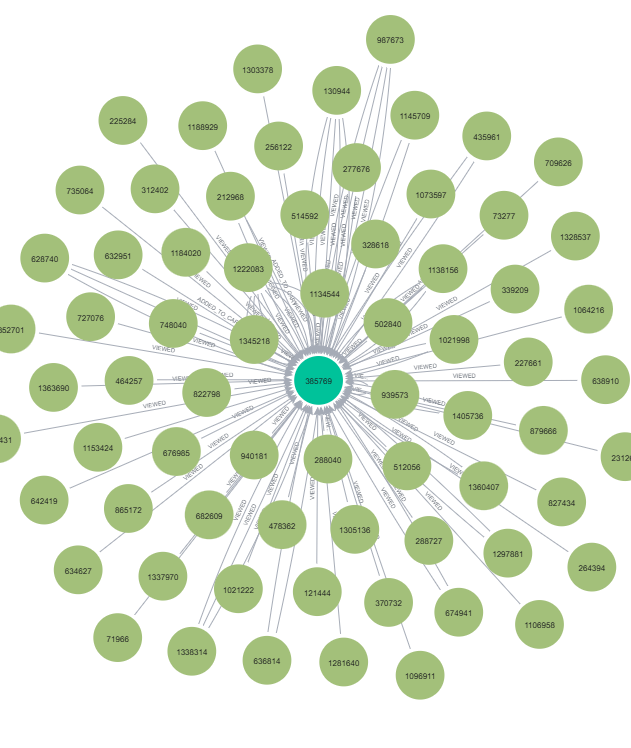

Graf sebelum similarity terdiri atas node Visitor dan Item yang dihubungkan oleh relasi VIEWED, ADDED_TO_CART, dan BOUGHT. Relasi tersebut merepresentasikan aktivitas pengunjung terhadap item.

### sesudah similarity

MATCH (a:Item {itemId: 5411})-[r:SIMILAR_TO]->(b:Item)

RETURN a, r, b

![setelah similarity.png](<attachment:setelah similarity.png>)
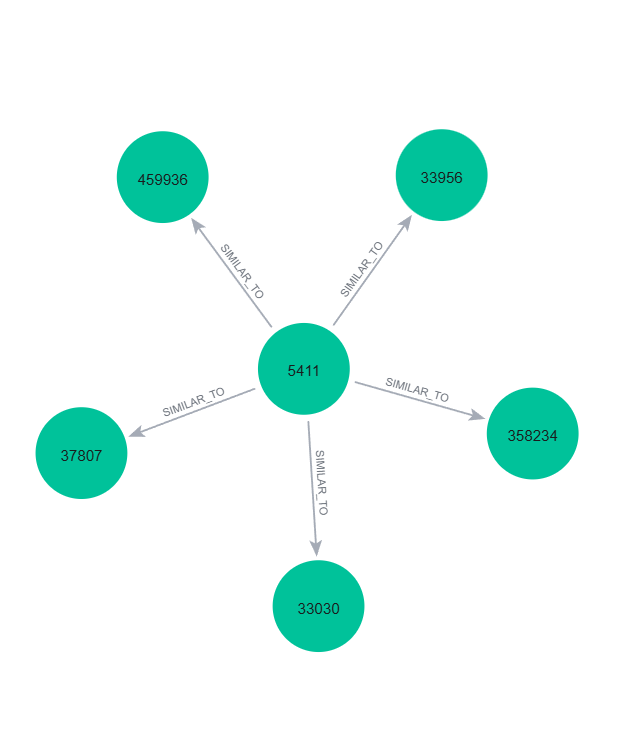

Setelah perhitungan similarity, graf diperluas dengan relasi SIMILAR_TO yang menghubungkan Item acuan dengan Item lain yang memiliki kemiripan pola interaksi. Nilai similarity disimpan sebagai properti pada relasi tersebut.

# 2.2 Analytics

## 1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

### a. tuliskan skrip Python dalam merekomendasikan KNN-nya!

In [26]:
# Pilih satu User secara acak dengan hasil yang dapat diulang
random_state = 42
rng = np.random.default_rng(random_state)

daftar_user = np.array(list(user_to_idx.keys()))
user_terpilih = rng.choice(daftar_user)

print("Random state:", random_state)
print("User terpilih:", user_terpilih)
print("Indeks User:", user_to_idx[user_terpilih])

Random state: 42
User terpilih: 596975
Indeks User: 60603


cari 5 user tetanggan dengan KNN

In [27]:
from sklearn.preprocessing import normalize

# Pastikan VSM berbentuk sparse matrix
X_user = X_user.tocsr()

# Ubah ID User menjadi indeks baris
target_idx = user_to_idx[user_terpilih]

# Hitung cosine similarity antar User terpilih dan semua User
X_user_norm = normalize(X_user, norm="l2", axis=1)
similarities = (
    X_user_norm @ X_user_norm[target_idx].T
).toarray().ravel()

# User tidak boleh menjadi tetangga bagi dirinya sendiri
similarities[target_idx] = -1

# Ambil 5 tetangga dengan similarity tertinggi
k = 5
neighbor_indices = np.argsort(similarities)[::-1]
neighbor_indices = [
    idx for idx in neighbor_indices
    if similarities[idx] > 0
][:k]

idx_to_user = {
    idx: uid for uid, idx in user_to_idx.items()
}

print("User target:", user_terpilih)
print("Jumlah tetangga yang ditemukan:", len(neighbor_indices))

for rank, idx in enumerate(neighbor_indices, start=1):
    print(
        f"{rank}. User {idx_to_user[idx]} "
        f"| Similarity: {similarities[idx]:.6f}"
    )

User target: 596975
Jumlah tetangga yang ditemukan: 3
1. User 650070 | Similarity: 1.000000
2. User 1395871 | Similarity: 0.707107
3. User 1339251 | Similarity: 0.577350


### b. berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya! 

Mencari Item yang pernah berinteraksi dengan para tetangga, tetapi belum pernah berinteraksi dengan User target

In [28]:
# Pastikan indeks Item dapat diterjemahkan kembali menjadi ID
idx_to_item = {
    idx: item_id for item_id, idx in item_to_idx.items()
}

if len(neighbor_indices) == 0:
    print("Belum ada tetangga dengan similarity positif.")
else:
    # Bobot = similarity setiap tetangga
    neighbor_weights = similarities[neighbor_indices]

    # Hitung skor setiap Item dari interaksi para tetangga
    scores = np.asarray(
        X_user[neighbor_indices].T @ neighbor_weights
    ).ravel()

    # Item yang sudah pernah berinteraksi dengan User target tidak boleh direkomendasikan kembali
    seen_items = set(X_user[target_idx].indices)
    scores[list(seen_items)] = -1

    # Urutkan Item berdasarkan skor tertinggi
    ranked_items = np.argsort(scores)[::-1]
    recommended_indices = [
        idx for idx in ranked_items if scores[idx] > 0
    ][:3]

    print("User target:", user_terpilih)
    print("Parameter k:", k)
    print("\n=== 3 Rekomendasi Item ===")

    for rank, idx in enumerate(recommended_indices, start=1):
        print(
            f"{rank}. Item {idx_to_item[idx]} "
            f"| Skor rekomendasi: {scores[idx]:.6f}"
        )

    if len(recommended_indices) < 3:
        print(
            "\nCatatan: hanya ditemukan",
            len(recommended_indices),
            "Item yang memenuhi kriteria rekomendasi."
        )

User target: 596975
Parameter k: 5

=== 3 Rekomendasi Item ===
1. Item 117192 | Skor rekomendasi: 0.707107
2. Item 310403 | Skor rekomendasi: 0.577350
3. Item 289069 | Skor rekomendasi: 0.577350


Seorang User dipilih secara acak menggunakan generator acak dengan `random_state = 42`, sehingga proses pemilihan dapat direproduksi selama daftar User tidak berubah.

Sistem rekomendasi menggunakan pendekatan User-based K-Nearest Neighbors (KNN) dengan \(k=5\). Kemiripan antar-User dihitung menggunakan cosine similarity berdasarkan matriks interaksi User–Item dari data training.

Lima User dengan kemiripan tertinggi digunakan sebagai tetangga. Item yang telah berinteraksi dengan User target dikeluarkan dari kandidat rekomendasi. Item yang belum pernah diakses kemudian diurutkan berdasarkan skor berbobot similarity, dan tiga Item dengan skor tertinggi dipilih sebagai rekomendasi.

**Hasil eksperimen:**
- User terpilih: [596975]
- Nilai \(k\): 5
- Rekomendasi Item 1: [117192]
- Rekomendasi Item 2: [310403]
- Rekomendasi Item 3: [289069]

## 2.  Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah: 

In [29]:
testing_path = "hasil_filter/events_testing.csv"
df_testing = pd.read_csv(testing_path)

print("Ukuran data testing:", df_testing.shape)
print("Kolom:", df_testing.columns.tolist())
display(df_testing.head())

Ukuran data testing: (288220, 6)
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'datetime']


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1439863633846,485689,view,439089,NaN,2015-08-18 02:07:13.846
1,1439861184957,59770,view,358963,NaN,2015-08-18 01:26:24.957
2,1439862453723,348230,view,54345,NaN,2015-08-18 01:47:33.723
3,1439864124731,1291065,view,53857,NaN,2015-08-18 02:15:24.731
4,1439862491992,529149,view,226978,NaN,2015-08-18 01:48:11.992


cari user yang ada di training dan testing

In [41]:
# Jumlah Item unik per User
jumlah_item_per_user = np.diff(X_user.indptr)

# User yang ada di training dan testing
testing_users = set(
    df_testing["visitorid"].dropna().astype(str).unique()
)

training_users = set(map(str, user_to_idx.keys()))
common_users = training_users & testing_users

# User yang punya minimal 2 Item di training
kandidat_user = [
    uid for uid in common_users
    if jumlah_item_per_user[
        user_to_idx[int(uid)] if int(uid) in user_to_idx
        else user_to_idx[uid]
    ] >= 2
]

print("Jumlah User di training dan testing:", len(common_users))
print("Jumlah kandidat dengan minimal 2 Item:", len(kandidat_user))

Jumlah User di training dan testing: 10227
Jumlah kandidat dengan minimal 2 Item: 4361


In [42]:
# Pilih User secara acak dengan seed tetap
rng = np.random.default_rng(42)
user_terpilih = str(rng.choice(sorted(kandidat_user)))

# Cocokkan ID User dengan tipe key di user_to_idx
if user_terpilih in user_to_idx:
    user_key = user_terpilih
else:
    user_key = int(user_terpilih)

target_idx = user_to_idx[user_key]

# Ambil Item relevan dari data testing
testing_user = df_testing[
    df_testing["visitorid"].astype(str) == user_terpilih
]
relevant_items = set(
    testing_user["itemid"].dropna().astype(str)
)

print("User yang akan dievaluasi:", user_terpilih)
print("Indeks User training:", target_idx)
print("Jumlah Item training:", X_user[target_idx].getnnz())
print("Jumlah Item relevan di testing:", len(relevant_items))

User yang akan dievaluasi: 1123862
Indeks User training: 132046
Jumlah Item training: 2
Jumlah Item relevan di testing: 1


Membuat rekomendasi KKN

In [46]:
# Item yang sudah dimiliki User target
seen_items = set(X_user[target_idx].indices)

# Urutkan semua User berdasarkan similarity tertinggi
candidate_neighbors = np.argsort(similarities)[::-1]

neighbor_indices = []
candidate_items = set()

for idx in candidate_neighbors:
    if idx == target_idx or similarities[idx] <= 0:
        continue

    # Item milik tetangga yang belum dimiliki User target
    neighbor_items = set(X_user[idx].indices)
    new_items = neighbor_items - seen_items

    # Pilih tetangga jika memiliki Item baru
    if new_items:
        neighbor_indices.append(idx)
        candidate_items.update(new_items)

    if len(neighbor_indices) == 5:
        break

print("Jumlah tetangga terpilih:", len(neighbor_indices))
print("Jumlah kandidat Item baru:", len(candidate_items))

Jumlah tetangga terpilih: 5
Jumlah kandidat Item baru: 8


In [47]:
neighbor_weights = similarities[neighbor_indices]

scores = np.asarray(
    X_user[neighbor_indices].T @ neighbor_weights
).ravel()

# Hilangkan Item yang sudah pernah dimiliki User target
scores[list(seen_items)] = 0

ranked_indices = np.argsort(scores)[::-1]

recommended_indices = [
    idx for idx in ranked_indices
    if scores[idx] > 0
][:5]

recommended_items = [
    str(idx_to_item[idx])
    for idx in recommended_indices
]

print("\nRekomendasi Top-5:")
for rank, item_id in enumerate(recommended_items, start=1):
    print(f"{rank}. Item ID: {item_id}")


Rekomendasi Top-5:
1. Item ID: 414425
2. Item ID: 457522
3. Item ID: 447422
4. Item ID: 109223
5. Item ID: 153982


### a. Hit@5 

In [49]:
# Pastikan ID Item memiliki tipe data yang sama
recommended_items = [str(item) for item in recommended_items]
relevant_items = set(map(str, relevant_items))

# Hitung relevansi setiap rekomendasi
hits = [
    int(item in relevant_items)
    for item in recommended_items[:5]
]

# Hit@5: apakah ada minimal satu Item relevan di Top-5?
hit_at_5 = int(sum(hits) > 0)

print("User yang dievaluasi:", user_key)
print("Item relevan di testing:", relevant_items)
print("Rekomendasi Top-5:", recommended_items)
print("Indikator relevansi:", hits)
print("Hit@5:", hit_at_5)

User yang dievaluasi: 1123862
Item relevan di testing: {'59140'}
Rekomendasi Top-5: ['414425', '457522', '447422', '109223', '153982']
Indikator relevansi: [0, 0, 0, 0, 0]
Hit@5: 0


### b. NDCG@5 

In [50]:
# DCG@5
dcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(hits, start=1)
)

# IDCG@5: nilai DCG ideal
ideal_length = min(5, len(relevant_items))

idcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, ideal_length + 1)
)

# NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else np.nan
)

print("DCG@5:", round(dcg_at_5, 4))
print("IDCG@5:", round(idcg_at_5, 4))
print("NDCG@5:", round(ndcg_at_5, 4))

DCG@5: 0.0
IDCG@5: 1.0
NDCG@5: 0.0


Evaluasi sistem rekomendasi menggunakan algoritma K-Nearest Neighbors (KNN) dilakukan pada User dengan ID 1123862 menggunakan metrik Hit@5 dan NDCG@5. Sistem menghasilkan lima rekomendasi Item, yaitu 414425, 457522, 447422, 109223, dan 153982. Berdasarkan data testing, terdapat satu Item relevan, yaitu Item 59140. Namun, Item tersebut tidak ditemukan dalam daftar rekomendasi Top-5, sehingga diperoleh nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0. Hasil ini menunjukkan bahwa model belum berhasil merekomendasikan Item relevan untuk User yang dievaluasi pada batas lima rekomendasi teratas.